In [2]:
import anndata as ad
import squidpy as sq
import cellcharter as cc
import pandas as pd
import scanpy as sc
import scvi
import numpy as np
import matplotlib.pyplot as plt
from lightning.pytorch import seed_everything

seed_everything(12345)

import os
import bbknn
from scipy import sparse
import matplotlib.pyplot as plt
from typing import List, Tuple
from typing import Union, List

Seed set to 12345


In [3]:
adata = sc.read("./visiumHD_spatial_analysis.h5ad")

In [4]:
adata.obsm['spatial'] = adata.obsm['X_spatial']

adata

AnnData object with n_obs × n_vars = 122372 × 15284
    obs: 'orig.ident', 'nCount_Spatial.Polygons', 'nFeature_Spatial.Polygons', 'group', 'nCount_Spatial', 'nFeature_Spatial', 'Cell_Anno', 'Type', 'niche', 'Celltype', 'celltype', 'barcode', 'condition', 'n_counts', 'batch'
    var: 'n_counts'
    uns: 'Cell_Anno_colors', 'log1p', 'spatial_neighbors'
    obsm: 'X_pca', 'X_spatial', 'X_umap', 'spatial'
    layers: 'counts'
    obsp: 'spatial_connectivities', 'spatial_distances'

In [68]:
## Define functions
#### Partition other cells by their neighborhood radius to the target cells
#######################################
import numpy as np
import scanpy as sc
from scipy.spatial.distance import cdist
from typing import List, Tuple

def get_cells_by_distance_to_target(
    adata,
    cell_type_col: str = "Celltype",
    target_cell: str = "A",
    radius_ranges: List[Tuple[float, float]] = [(0, 0), (0, 20), (20, 60), (60, 200), (200, 5000)],
    slide_col: str = "sample"  # slide column must be specified
):
    """
    Compute, per slide, the distance from each cell to the nearest target cell, and bin the distances into radius ranges
    (this version keeps the target cells; target cells get distance 0 and fall into the 0-0 bin)
    
    Parameters:
        adata: AnnData object
        cell_type_col: cell type column name
        target_cell: target cell type
        radius_ranges: list of distance ranges [(min, max), ...]
        slide_col: slide grouping column name (required)
    
    Returns:
        AnnData subset with the added columns:
        - min_distance: distance to the nearest target cell
        - nearest_target: ID of the nearest target cell
        - radius_range: the distance range it belongs to
    """
    adata = adata.copy()
    
    if slide_col is None:
        raise ValueError("The slide_col argument is required for per-slide computation")
    
    # Process grouped by slide
    slides = adata.obs[slide_col].unique()
    all_results = []
    
    for slide in slides:
        # Get the cells of the current slide
        slide_mask = adata.obs[slide_col] == slide
        adata_slide = adata[slide_mask].copy()
        
        # Process the current slide
        slide_result = _calculate_min_distance_per_slide(
            adata_slide, 
            cell_type_col, 
            target_cell, 
            radius_ranges
        )
        
        if slide_result is not None:
            # Add slide information
            slide_result.obs['slide'] = slide
            all_results.append(slide_result)
    
    if not all_results:
        print("Warning: no target cells found")
        return None
    
    # Merge all slide results
    adata_sub = sc.concat(all_results)
    
    # Key change: remove the original non_target_mask filtering and keep all valid cells, including target cells
    return adata_sub


def _calculate_min_distance_per_slide(
    adata,
    cell_type_col: str,
    target_cell: str,
    radius_ranges: List[Tuple[float, float]]
):
    """Core function: compute each cell to nearest target-cell distance for a single slide"""
    
    # Get target cell coordinates and names
    target_mask = adata.obs[cell_type_col] == target_cell
    
    if not target_mask.any():
        print(f"Warning: no target cell '{target_cell}' found in the current slide")
        return None
        
    target_coords = adata[target_mask].obsm['spatial']
    target_names = adata.obs_names[target_mask].tolist()
    
    # Get coordinates of all cells
    all_coords = adata.obsm['spatial']
    
    # Use cdist instead of the original double for loop to greatly speed up computation
    distances = cdist(all_coords, target_coords)
    
    # Find the minimum distance from each cell to all target cells and its index
    min_distances = np.min(distances, axis=1)
    min_indices = np.argmin(distances, axis=1)
    
    # Map back to the target cell names
    nearest_targets = [target_names[idx] for idx in min_indices]
    
    # Add the results to obs
    adata.obs['min_distance'] = min_distances
    adata.obs['nearest_target'] = nearest_targets
    
    # Assign distance ranges
    radius_labels = []
    
    for d in min_distances:
        label = None
        for r_min, r_max in radius_ranges:
            # Logic specific to target cells: only an exact 0 goes into 0-0
            if r_min == 0 and r_max == 0:
                if d == 0.0:
                    label = "0-0"
                    break
            # Logic for other ranges: use left-open right-closed (r_min < d <= r_max) so distance 0 is not counted into 0-20
            elif r_min == 0:
                if 0 < d <= r_max:
                    label = f"{r_min}-{r_max}"
                    break
            else:
                if r_min < d <= r_max:
                    label = f"{r_min}-{r_max}"
                    break
                    
        radius_labels.append(label)
    
    adata.obs['radius_range'] = radius_labels
    
    # Filter out cells beyond all ranges (if the maximum is 5000, cells beyond 5000 are discarded)
    valid_mask = ~adata.obs['radius_range'].isna()
    valid_cells = adata[valid_mask].copy()
    
    return valid_cells

In [74]:
# Get the neighboring cells of the target cells by different radius ranges and label the radius range
adata_sub = get_cells_by_distance_to_target(
    adata,
    cell_type_col="Cell_Anno",
    target_cell="SC",##target cell
    radius_ranges=[(0, 0), (1, 20), (20, 60), (60, 200),(200,5000)],
    slide_col="group"  # obs column name indicating different slides
)

In [70]:
adata_sub.obs['group'].unique()

['CON3', 'CON6', 'CON9', 'MP1', 'MP2', ..., 'MP9', 'CON2', 'MP11', 'MP3', 'CON5']
Length: 11
Categories (11, object): ['CON2', 'CON3', 'CON5', 'CON6', ..., 'MP3', 'MP6', 'MP9', 'MP11']

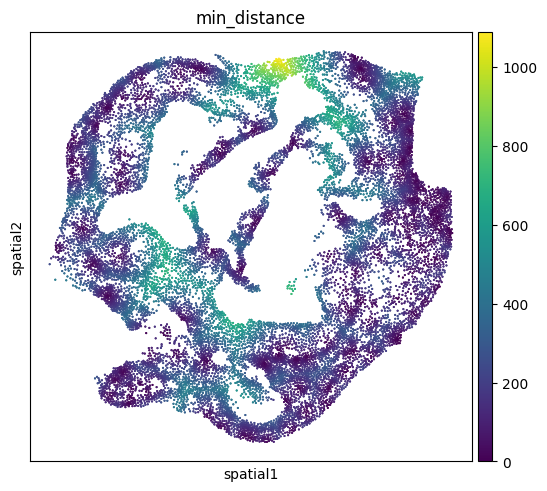

In [75]:
sq.pl.spatial_scatter(
    adata_sub,
    library_key='group',
    library_id="MP1",
    shape=None,
    color=[
        "min_distance",
    ],
    wspace=0.4,
)
#plt.savefig( './intima_to_adventitia_schematic.pdf', bbox_inches='tight',  dpi=500)   

In [76]:
adata_sub.obs.to_csv("./SC radius_neighborhood.csv")

In [60]:
import numpy as np
import scanpy as sc
from scipy.spatial.distance import cdist

def calculate_vertical_distance(
    adata,
    niche_col="banksy_niche",
    source_niche=["niche_3"], 
    target_niche=["niche_1", "niche_4", "niche_6"],
    slide_col="group",
    coord_key="spatial"
):
    """
    Compute the minimum spatial distance from source-niche cells to target-niche cells within each group.
    Modified version: the returned AnnData includes both source and target cells, and target cells are assigned a distance of 0 directly.
    
    Parameters:
    -----------
    adata : AnnData
        Annotated data matrix containing spatial coordinates
    niche_col : str, optional (default: "banksy_niche")
        Column name in adata.obs storing the niche classification
    source_niche : str or list, optional (default: ["niche_3"])
        Source niche name or list to compute distances from
    target_niche : str or list, optional (default: ["niche_1", "niche_4", "niche_6"])
        Target niche list; compute the minimum distance to these niches
    slide_col : str, optional (default: "group")
        Column name in adata.obs storing the group/slide information
    coord_key : str, optional (default: "spatial")
        Key name in adata.obsm storing the spatial coordinates
    
    Returns:
    --------
    AnnData
        Subset containing source and target niche cells; a 'vertical_distance' column storing the minimum distance is added to obs
    """
    
    # 1. Unify the format: allow passing a single string or a list
    if isinstance(source_niche, str):
        source_niche = [source_niche]
    if isinstance(target_niche, str):
        target_niche = [target_niche]

    # Get the boolean masks for source and target
    source_mask = adata.obs[niche_col].isin(source_niche)
    target_mask = adata.obs[niche_col].isin(target_niche)
    
    # 2. Key change: combine source and target to extract the subset
    combined_mask = source_mask | target_mask
    adata_vertical = adata[combined_mask].copy()
    
    # If no target niche cells are found, return the result with a warning
    if not target_mask.any():
        print(f"Warning: no target niche cells {target_niche} found")
        adata_vertical.obs['vertical_distance'] = np.nan
        return adata_vertical
    
    # Get the spatial coordinates
    if coord_key not in adata.obsm:
        raise KeyError(f"Spatial coordinate key '{coord_key}' not found in adata.obsm")
    coords = adata.obsm[coord_key]
    
    # Get all groups/slides
    slides = adata.obs[slide_col].unique()
    
    # 3. Initialize the distance array (filled with np.nan by default, then set the distance of target_niche to 0)
    vertical_distances = np.full(adata_vertical.shape[0], np.nan)
    target_in_vertical = adata_vertical.obs[niche_col].isin(target_niche)
    vertical_distances[target_in_vertical] = 0.0 # force the target distance to 0
    
    for slide in slides:
        # Get the cells of the current group
        slide_mask = adata.obs[slide_col] == slide
        
        # Source-niche and target-niche cells in the current group
        source_in_slide = slide_mask & source_mask
        target_in_slide = slide_mask & target_mask
        
        # If the current group has no source or target cells, skip the distance computation for this slide
        if not source_in_slide.any() or not target_in_slide.any():
            continue
            
        # Get coordinates
        source_coords = coords[source_in_slide]
        target_coords = coords[target_in_slide]
        
        # Compute the distance matrix (rows: source cells, columns: target cells)
        distances = cdist(source_coords, target_coords)
        
        # Find the minimum distance from each source cell to the target cells
        min_distances = np.min(distances, axis=1)
        
        # Store the source computation results by matching indices
        slide_source_indices = adata.obs.index[source_in_slide]
        vertical_mask = adata_vertical.obs.index.isin(slide_source_indices)
        vertical_distances[vertical_mask] = min_distances
    
    # Add the distance to obs
    adata_vertical.obs['vertical_distance'] = vertical_distances
    
    return adata_vertical

In [77]:
# Compute the distance from each point in the plaque to one or more niches (spatial domains)

adata_vertical = calculate_vertical_distance(
    adata,
    niche_col="niche",
    source_niche=["niche2",'niche3','niche4'],
    target_niche=["niche1"],
    slide_col="group"
)

In [82]:
adata_vertical = adata_vertical[adata_vertical.obs['vertical_distance'] < 700]

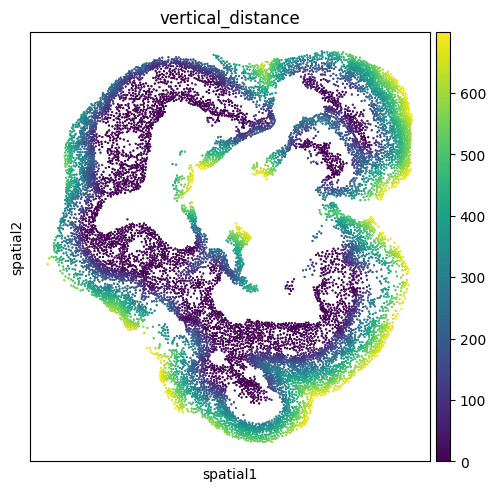

In [83]:
sq.pl.spatial_scatter(
    adata_vertical,
    library_key='group',
    library_id="MP1",
    shape=None,
    color=[
        "vertical_distance",
    ],
    wspace=0.4,
)

In [66]:
adata_vertical.obs.to_csv("./vertical_distance niche124.csv")

In [36]:
########################
## Use neighborhood distances to separate each lesion and compute the distance from each cell in the lesion to the centroid
from typing import Optional, Union
import numpy as np
import pandas as pd
import scanpy as sc
from sklearn.cluster import DBSCAN
from scipy.spatial import distance
from tqdm import tqdm

def identify_lesions(
    adata: sc.AnnData,
    niche_col: str = "banksy_niche",
    target_niche: str = "niche_3",
    slide_col: str = "sample",
    eps: float = 150,
    min_cells_per_lesion: int = 30,
    distance_percentile: float = 95,
    return_subset: bool = True,
    random_seed: Optional[int] = None
) -> Union[sc.AnnData, None]:
    """
    Identify lesion regions in spatial transcriptomics data (based on DBSCAN clustering)
    
    Parameters:
        adata: AnnData object (must contain spatial coordinates)
        niche_col: column name storing the niche information
        target_niche: niche type to analyze
        slide_col: slide grouping column name
        eps: DBSCAN neighborhood radius (same unit as the coordinates)
        min_cells_per_lesion: minimum number of cells per lesion
        distance_percentile: long-edge filtering threshold (percentile)
        return_subset: whether to return only the subset of target niche cells
        random_seed: random seed (ensures reproducibility)
    
    Returns:
        Returns depending on the return_subset argument:
        - True: AnnData subset containing only target_niche cells
        - False: the original adata object (with added lesion_id and distance_to_centroid columns)
        - None: if no target_niche cells are found
    
    Added columns:
        - lesion_id: lesion region ID (format: {slide}_lesion_{cluster_id})
        - distance_to_centroid: distance from the cell to the centroid of its lesion
    """
    if random_seed is not None:
        np.random.seed(random_seed)
    
    # Initialize the result columns
    adata = adata.copy()
    adata.obs['lesion_id'] = 'isolated'
    adata.obs['distance_to_centroid'] = np.nan
    
    # Extract the target niche cells
    target_mask = adata.obs[niche_col] == target_niche
    if not any(target_mask):
        print(f"Warning: no {target_niche} cells found")
        return None
    
    adata_target = adata[target_mask].copy()
    
    # Process grouped by slide
    for slide in tqdm(adata_target.obs[slide_col].unique(), desc="Processing slides"):
        slide_mask = (adata_target.obs[slide_col] == slide)
        adata_slide = adata_target[slide_mask].copy()
        coords = adata_slide.obsm['spatial'][:, :2]  # take the XY coordinates
        
        # DBSCAN clustering
        dbscan = DBSCAN(
            eps=eps,
            min_samples=min_cells_per_lesion
        )
        clusters = dbscan.fit_predict(coords)
        
        # Assign lesion labels
        for cluster_id in np.unique(clusters):
            if cluster_id == -1:
                continue  # skip noise points
                
            cluster_mask = (clusters == cluster_id)
            lesion_id = f"{slide}_lesion_{cluster_id}"
            adata_slide.obs.loc[cluster_mask, 'lesion_id'] = lesion_id
            
            # Compute the distance from the cell to the centroid
            cluster_coords = coords[cluster_mask]
            centroid = np.mean(cluster_coords, axis=0)
            distances = distance.cdist(cluster_coords, [centroid], 'euclidean').flatten()
            adata_slide.obs.loc[cluster_mask, 'distance_to_centroid'] = distances
        
        # Merge the results back into the original data
        adata.obs.loc[adata_slide.obs.index, 'lesion_id'] = adata_slide.obs['lesion_id']
        adata.obs.loc[adata_slide.obs.index, 'distance_to_centroid'] = adata_slide.obs['distance_to_centroid']
    
    # Summary statistics
    lesion_stats = adata.obs[adata.obs['lesion_id'] != 'isolated']
    if not lesion_stats.empty:
        print("===== Lesion region statistics =====")
        print(f"Total number of lesions: {lesion_stats['lesion_id'].nunique()}")
        print("\nLesion distribution per slide:")
        print(lesion_stats.groupby([slide_col, 'lesion_id']).size())
    else:
        print("Warning: no lesion region identified")
    
    return adata[target_mask].copy() if return_subset else adata

In [38]:
adata.obs['lesion'] = adata.obs['domain'].apply(lambda x: 'lesion' if x in ['Inflamed lesion', 'Relatively diseased wall'] else 'others')


In [37]:
adata_lesions = identify_lesions(
    adata,
    niche_col="niche",
    target_niche="niche1",
    slide_col="group",
    eps=100,
    min_cells_per_lesion=30
)

Processing slides: 100%|████████████████████████████████████████████████████████████████| 11/11 [00:00<00:00, 42.76it/s]
/tmp/ipykernel_2704/3775429659.py:100: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(lesion_stats.groupby([slide_col, 'lesion_id']).size())


===== Lesion region statistics =====
Total number of lesions: 94

Lesion distribution per slide:
group  lesion_id    
CON2   CON2_lesion_0    675
       CON2_lesion_1    157
       CON2_lesion_2     52
       CON2_lesion_3     30
       CON2_lesion_4    138
                       ... 
MP11   MP9_lesion_5       0
       MP9_lesion_6       0
       MP9_lesion_7       0
       MP9_lesion_8       0
       MP9_lesion_9       0
Length: 1034, dtype: int64


In [41]:
adata_lesions.obs.to_csv("./centroid_distance.csv")

In [19]:
adata_lesions.obs['group'].unique()

['CWD266', 'CWD297', 'CWD299', 'IWD368', 'IWD374', 'IWD265', 'IWD239', 'IWD260', 'IWD305']
Categories (9, object): ['CWD266', 'CWD297', 'CWD299', 'IWD239', ..., 'IWD265', 'IWD305', 'IWD368', 'IWD374']

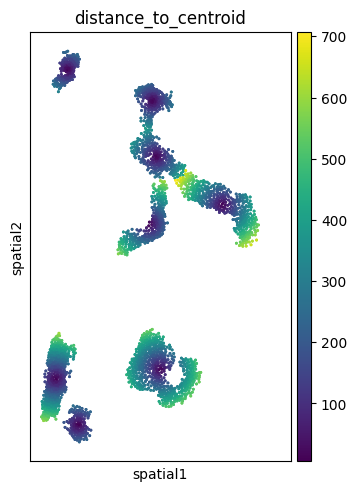

In [40]:
sq.pl.spatial_scatter(
    adata_lesions,
    library_key='group',
    library_id="MP11",
    shape=None,
    color=["distance_to_centroid" ],
    wspace=0.4,
)
#plt.savefig( './lesion_centroid_schematic.pdf', bbox_inches='tight',  dpi=500)   